In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import ot

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42  
mpl.rcParams['ps.fonttype'] = 42

In [3]:
import os
os.chdir("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/")

In [4]:
rna = sc.read_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/Yao-2021-RNA.h5ad")
atac = sc.read_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/Yao-2021-ATAC.h5ad")
st = sc.read_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/merfish.h5ad")

processing of st

In [5]:
st

AnnData object with n_obs × n_vars = 276556 × 254
    obs: 'fovID', 'fov_x', 'fov_y', 'volume', 'center_x', 'center_y', 'slice_id', 'sample_id', 'BICCN_cluster_label', 'BICCN_subclass_label', 'BICCN_class_label', 'BICCN_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'organism_ontology_term_id', 'donor_id', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'cell_type_ontology_term_id_colors', 'citation', 'donor_id_colors', 'schema_reference', 'schema_version', 'title'
    obsm: 'X_umap'
    layers: 'counts'

In [6]:
st.obs.slice_id.value_counts()

slice_id
mouse1_slice153    7439
mouse1_slice162    6759
mouse1_slice102    6731
mouse1_slice212    6469
mouse1_slice170    6319
                   ... 
mouse2_slice31     2037
mouse1_slice21     2033
mouse2_slice1      1706
mouse2_slice10     1160
mouse2_slice20      670
Name: count, Length: 64, dtype: int64

In [7]:
st = st[st.obs.slice_id=="mouse1_slice170",:]
st.var_names = st.var['feature_name'].str.split('_').str[0]
st.obsm['X_spatial'] = st.obs.loc[:,['center_x', 'center_y']].to_numpy().copy()

In [8]:
st

AnnData object with n_obs × n_vars = 6319 × 254
    obs: 'fovID', 'fov_x', 'fov_y', 'volume', 'center_x', 'center_y', 'slice_id', 'sample_id', 'BICCN_cluster_label', 'BICCN_subclass_label', 'BICCN_class_label', 'BICCN_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'organism_ontology_term_id', 'donor_id', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'cell_type_ontology_term_id_colors', 'citation', 'donor_id_colors', 'schema_reference', 'schema_version', 'title'
    obsm: 'X_umap', 'X_spatial'
    layers: 'counts'

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


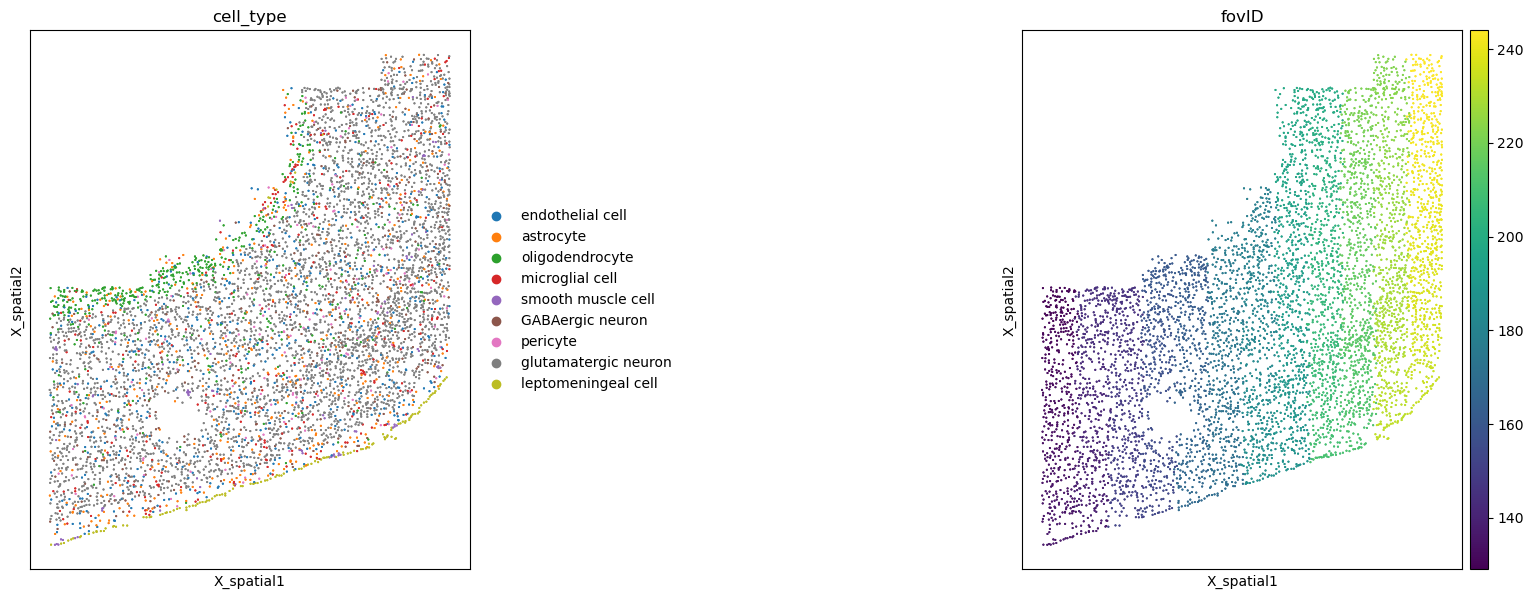

In [18]:
sq.pl.spatial_scatter(st, library_id=None,spatial_key = 'X_spatial', color=["cell_type",'fovID'],shape=None,size=1, figsize=(9, 7))

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


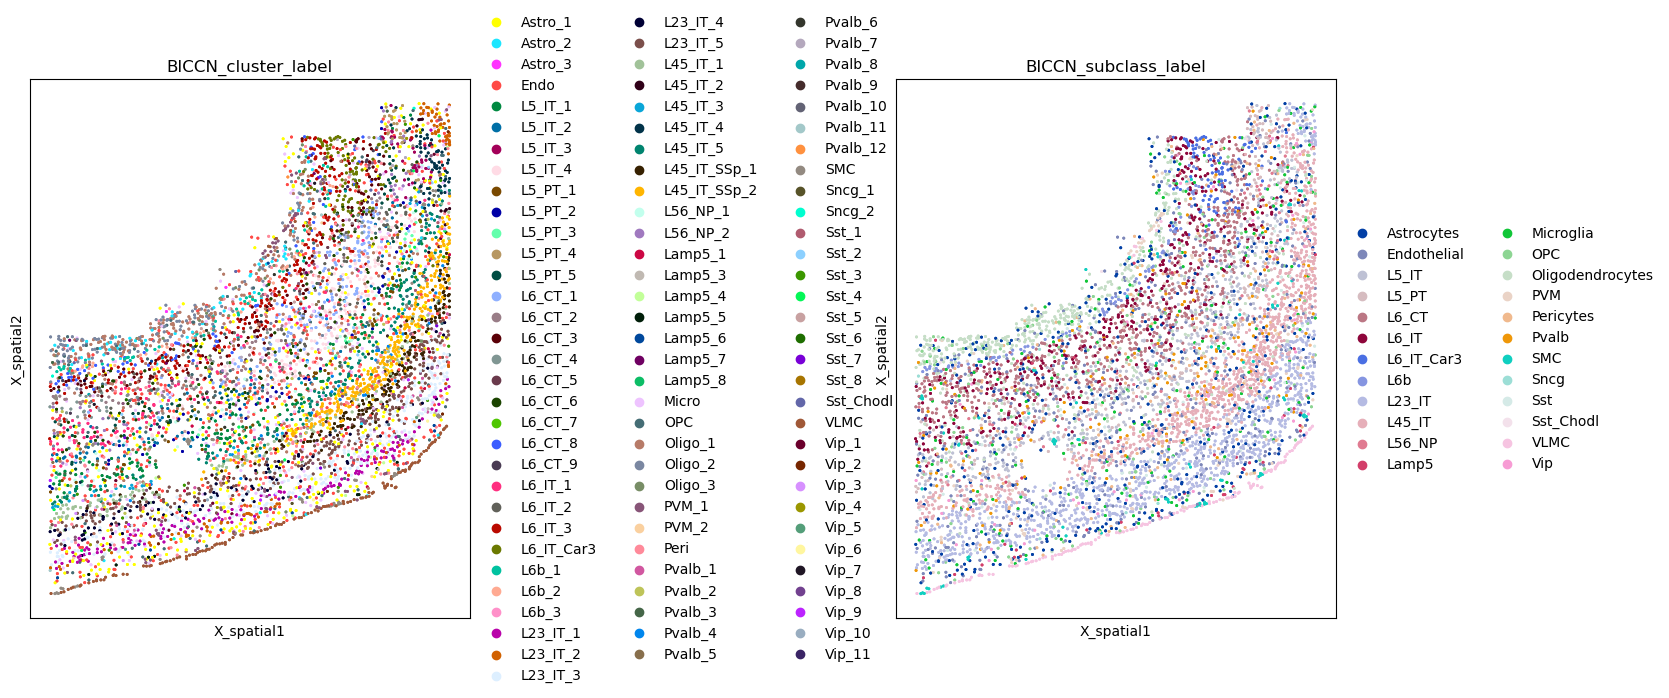

In [19]:
sq.pl.spatial_scatter(st, library_id=None,spatial_key = 'X_spatial', color=['BICCN_cluster_label','BICCN_subclass_label'],
                      shape=None,size=8, figsize=(9, 7))

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


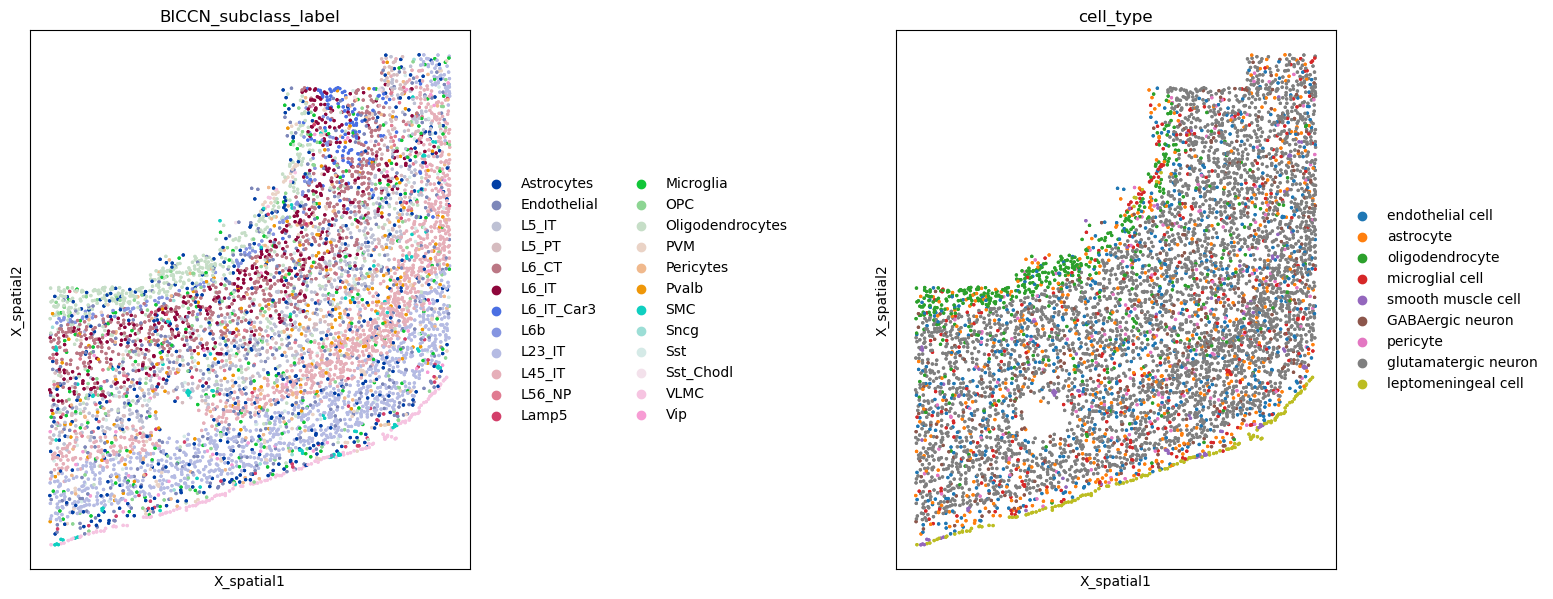

In [16]:
sq.pl.spatial_scatter(st, library_id=None,spatial_key = 'X_spatial', color=['BICCN_subclass_label',"cell_type"],
                      shape=None,size=8, figsize=(9, 7),save="_st.pdf")

processing of rna

In [20]:
rna

AnnData object with n_obs × n_vars = 69727 × 27123
    obs: 'x', 'cluster_label', 'subclass_label', 'class_label', 'cluster_color', 'size', 'aggr_num', 'umi.counts', 'gene.counts', 'library_id', 'tube_barcode', 'Seq_batch', 'Region', 'Lib_type', 'Gender', 'Donor', 'Amp_Name', 'Amp_Date', 'Amp_PCR_cyles', 'Lib_Name', 'Lib_Date', 'Replicate_Lib', 'Lib_PCR_cycles', 'Lib_PassFail', 'Cell_Capture', 'Lib_Cells', 'Mean_Reads_perCell', 'Median_Genes_perCell', 'Median_UMI_perCell', 'Saturation', 'Live_percent', 'Total_Cells', 'Live_Cells', 'method', 'exp_component_name', 'mapped_reads', 'unmapped_reads', 'nonconf_mapped_reads', 'total.reads', 'doublet.score', 'domain', 'protocol', 'dataset', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'chrom', 'chromStart', 'chromEnd', 'name', 'score', 'strand', 'thickStart', 'thickEnd', 'itemRgb', 'blockCount', 'blockSizes', 'blockStarts', 'gene_type', 'gene_name', 'mgi_id', 'havana_gene', 'tag', 'n_counts', 'highly_variable', 'highly_variable_

In [21]:
rna.obs.Seq_batch.value_counts()

Seq_batch
RTX-841    39656
RTX-850    26071
RTX-842     4000
Name: count, dtype: int64

In [22]:
rna.obs.Donor.value_counts()

Donor
427378    24927
426003    18729
457909    14107
457911    11964
Name: count, dtype: int64

In [24]:
rna[rna.obs.Donor==457909,:].copy().obs['Seq_batch'].value_counts()

Seq_batch
RTX-850    14107
Name: count, dtype: int64

In [25]:
rna = rna[rna.obs.Donor==457909,:].copy()

processing of atac

In [26]:
atac

AnnData object with n_obs × n_vars = 54844 × 148814
    obs: 'sample', 'barcode', 'TN', 'UM', 'PP', 'UQ', 'CM', 'tsne_0', 'tsne_1', 'cluster', 'region', 'MajorCluster', 'SubCluster', 'domain', 'protocol', 'dataset', 'cell_type', 'batch'
    var: 'chrom', 'chromStart', 'chromEnd', 'genome', 'n_counts'

In [27]:
atac.obs.batch.value_counts()

batch
CEMBA180612_5D    7102
CEMBA180618_5D    6473
CEMBA171206_3C    6401
CEMBA180410_2C    6365
CEMBA180409_2C    6352
CEMBA171207_3C    5981
CEMBA171213_4B    5921
CEMBA180104_4B    5210
CEMBA171212_4B    5039
Name: count, dtype: int64

In [28]:
rna.layers['counts'] = rna.X.copy()
atac.layers['counts'] = atac.X.copy()
st.layers['counts'] = st.X.copy()

In [14]:
import episcanpy as epi
atac = epi.tl.geneactivity(atac, "/home/bingxing2/ailab/scxlab0179/mop/gencode.vM10.chr_patch_hapl_scaff.annotation.gtf",annotation='HAVANA')

In [15]:
rna.var_names_make_unique()
atac.var_names_make_unique()
st.var_names_make_unique()

In [16]:
atac.layers['counts'] = atac.X.copy()

In [17]:
atac.write_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/ATAC_gas.h5ad")

In [29]:
atac = sc.read_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/ATAC_gas.h5ad")

In [30]:
atac[atac.obs.batch.isin(['CEMBA180612_5D']),:].obs.cell_type.value_counts()

cell_type
L4/5 IT    1861
L2/3 IT    1597
L6 CT      1360
L6 IT       651
Pvalb       426
Sst         313
L5 ET       285
NP          218
Vip         174
Lamp5       172
Sncg         45
Name: count, dtype: int64

In [32]:
atac = atac[atac.obs.batch.isin(['CEMBA180612_5D']),:].copy()
st.obs['batch'] = "st"
rna.obs['batch'] = rna.obs.Seq_batch

In [33]:
# layers_type = ['L2/3 IT','L4/5 IT','L6 IT','L6 CT']
# rna = rna[rna.obs.cell_type.isin(layers_type),:].copy()
# atac = atac[atac.obs.cell_type.isin(layers_type),:].copy()

In [34]:
sc.pp.normalize_total(rna)
sc.pp.log1p(rna)
sc.pp.highly_variable_genes(rna,n_top_genes=3000) #batch_key="batch", , min_mean=0.02, max_mean=4, min_disp=0.5
genelist = rna.var.index[rna.var['highly_variable']==True]

In [35]:
sc.pp.normalize_total(atac)
sc.pp.log1p(atac)
sc.pp.highly_variable_genes(atac,n_top_genes=3000) #, batch_key="batch") #, min_mean=0.05, max_mean=1.5, min_disp=.5,, batch_key="batch"
peaklist = atac.var.index[atac.var['highly_variable']==True]

In [36]:
sc.pp.normalize_total(st)
sc.pp.log1p(st)
stlist = st.var_names

In [37]:
features = list(set(genelist) | set(peaklist) | set(stlist))
rna_feat = list(set(rna.var_names)&set(features))
atac_feat = list(set(atac.var_names)&set(features))
st_feat = list(set(st.var_names)&set(features))

In [38]:
print(len(rna_feat))
print(len(atac_feat))
print(len(st_feat))

4737
4550
254


In [39]:
len(features)

5548

In [40]:
import anndata as ad
adata = ad.concat([rna[:,rna_feat],atac[:,atac_feat],st[:,st_feat]],axis="obs",
                  join="outer",label="modality",keys=["rna","atac","st"])

In [41]:
adata.uns['rna_feat'] = rna_feat
adata.uns['atac_feat'] = atac_feat
adata.uns['st_feat'] = st_feat
adata.uns['rna_hvg'] = list(set(genelist) & set(adata.var_names))
adata.uns['atac_hvg'] = list(set(peaklist) & set(adata.var_names))
adata.uns['st_hvg'] = list(set(stlist) & set(adata.var_names))

In [42]:
st.var.gene_name = st.var_names
st.var.index = st.var.gene_name
st.var.index.name = "gene_name"

/tmp/ipykernel_3980336/2347273096.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  st.var.gene_name = st.var_names


In [43]:
rna[:,rna_feat].copy().write("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/rna_processed.h5ad")
atac[:,atac_feat].copy().write("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/atac_processed.h5ad")
st[:,st_feat].copy().write("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/st_processed.h5ad")

In [44]:
adata.write("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/merged.h5ad")

spatial imputation

In [6]:
import os
os.chdir("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/")

EMD

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/ot/lp/__init__.py:388: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  result_code_string = check_result(result_code)
/tmp/ipykernel_3543086/3542028578.py:16: RuntimeWarning: invalid value encountered in divide
  W = W / W.sum(axis=1, keepdims=True)
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


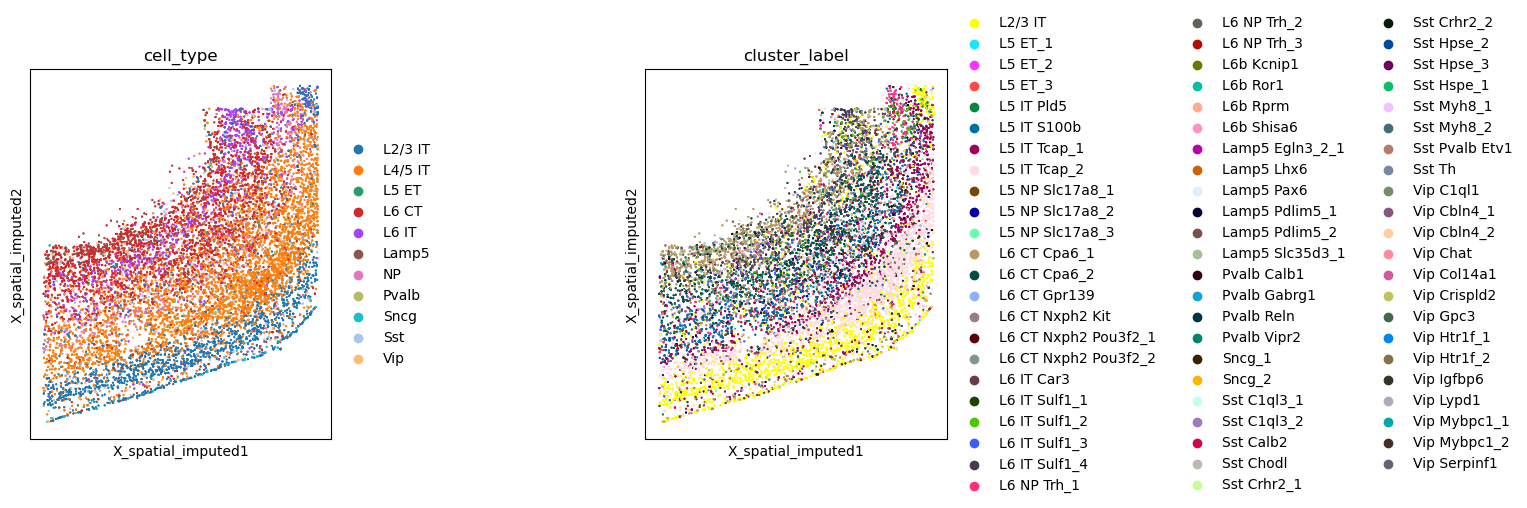

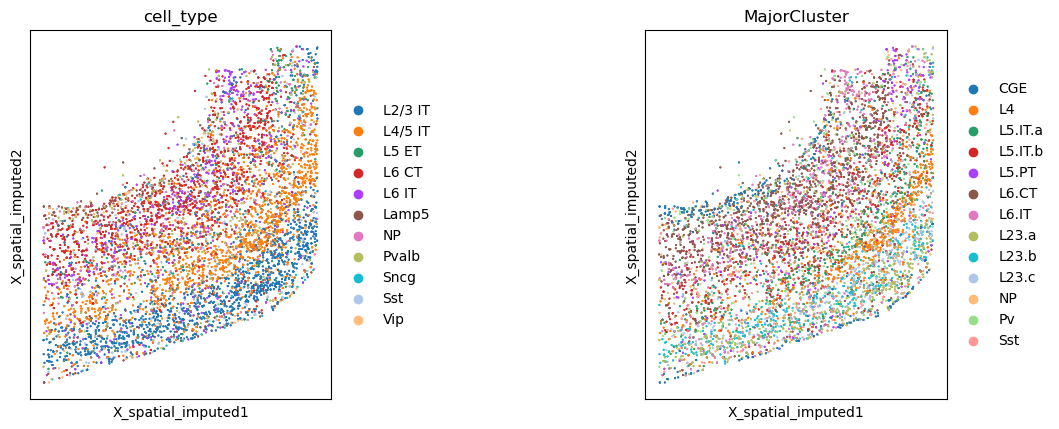

In [ ]:
adata = sc.read_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/adata_aligned_trained.h5ad")
locs = adata.obs.loc[:,['center_x', 'center_y']].to_numpy()
adata.obsm['X_spatial'] = locs.copy()
adata.obs['has_loc'] = adata.obs.modality=='st'
latent = adata.obsm['latent_shared']
z1 = latent[adata.obs.has_loc==0,:]
z2 = latent[adata.obs.has_loc==1,:]
r2 = adata[adata.obs.has_loc==1,:].obsm['X_spatial'].copy()
import ot
p = ot.unif(z1.shape[0])
q = ot.unif(z2.shape[0])
cost_matrix = ot.dist(z1, z2, metric='sqeuclidean')
cost_matrix = cost_matrix / np.max(cost_matrix)
W = ot.emd(p, q, cost_matrix) # ot.sinkhorn_unbalanced ,reg_m=1
W = W / W.sum(axis=1, keepdims=True)
r1 = W @ r2

adata.obsm['X_spatial_imputed'] = np.concatenate([r1,r2],axis=0)

sq.pl.spatial_scatter(adata[adata.obs.modality=="rna",:], library_id=None,spatial_key = 'X_spatial_imputed', 
                      color=["cell_type",'cluster_label'],shape=None,size=1, save="_rna_imputate_full.pdf")
sq.pl.spatial_scatter(adata[adata.obs.modality=="atac",:], library_id=None,spatial_key = 'X_spatial_imputed', 
                      color=["cell_type","MajorCluster"],shape=None,size=1, save="_atac_imputate_full.pdf")


In [ ]:
adata.write_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/adata_aligned_trained_full_imputed.h5ad")

Sinkhorn: more reg

In [2]:
adata = sc.read_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/adata_aligned_trained.h5ad")
adata

AnnData object with n_obs × n_vars = 27528 × 5548
    obs: 'x', 'cluster_label', 'subclass_label', 'class_label', 'cluster_color', 'size', 'aggr_num', 'umi.counts', 'gene.counts', 'library_id', 'tube_barcode', 'Seq_batch', 'Region', 'Lib_type', 'Gender', 'Donor', 'Amp_Name', 'Amp_Date', 'Amp_PCR_cyles', 'Lib_Name', 'Lib_Date', 'Replicate_Lib', 'Lib_PCR_cycles', 'Lib_PassFail', 'Cell_Capture', 'Lib_Cells', 'Mean_Reads_perCell', 'Median_Genes_perCell', 'Median_UMI_perCell', 'Saturation', 'Live_percent', 'Total_Cells', 'Live_Cells', 'method', 'exp_component_name', 'mapped_reads', 'unmapped_reads', 'nonconf_mapped_reads', 'total.reads', 'doublet.score', 'domain', 'protocol', 'dataset', 'cell_type', 'batch', 'sample', 'barcode', 'TN', 'UM', 'PP', 'UQ', 'CM', 'tsne_0', 'tsne_1', 'cluster', 'region', 'MajorCluster', 'SubCluster', 'fovID', 'fov_x', 'fov_y', 'volume', 'center_x', 'center_y', 'slice_id', 'sample_id', 'BICCN_cluster_label', 'BICCN_subclass_label', 'BICCN_class_label', 'BICCN_onto

In [ ]:
locs = adata.obs.loc[:,['center_x', 'center_y']].to_numpy()
adata.obsm['X_spatial'] = locs.copy()
adata.obs['has_loc'] = adata.obs.modality=='st'
latent = adata.obsm['latent_shared']
z1 = latent[adata.obs.has_loc==0,:]
z2 = latent[adata.obs.has_loc==1,:]
r2 = adata[adata.obs.has_loc==1,:].obsm['X_spatial'].copy()
import ot
p = ot.unif(z1.shape[0])
q = ot.unif(z2.shape[0])
cost_matrix = ot.dist(z1, z2, metric='sqeuclidean')
W = ot.sinkhorn(p, q, cost_matrix, reg=0.01) # ot.sinkhorn_unbalanced ,reg_m=1
W = W / W.sum(axis=1, keepdims=True)
r1 = W @ r2

adata.obsm['X_spatial_imputed'] = np.concatenate([r1,r2],axis=0)

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/ot/bregman/_sinkhorn.py:631: RuntimeWarning: divide by zero encountered in divide
  v = b / KtransposeU
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/ot/bregman/_sinkhorn.py:643: UserWarning: Warning: numerical errors at iteration 0
  warnings.warn("Warning: numerical errors at iteration %d" % ii)
/tmp/ipykernel_3543086/1522244194.py:14: RuntimeWarning: invalid value encountered in divide
  W = W / W.sum(axis=1, keepdims=True)


/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


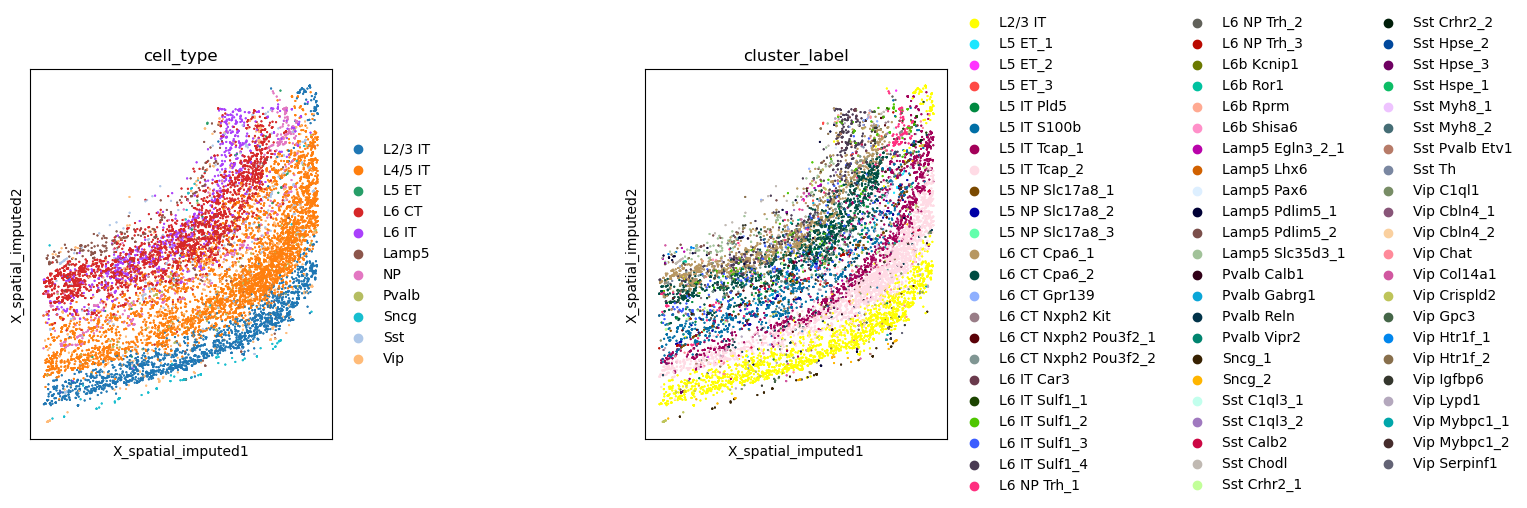

In [17]:
sq.pl.spatial_scatter(adata[adata.obs.modality=="rna",:], library_id=None,spatial_key = 'X_spatial_imputed', 
                      color=["cell_type",'cluster_label'],shape=None,size=1, save="_rna_imputate.pdf")

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


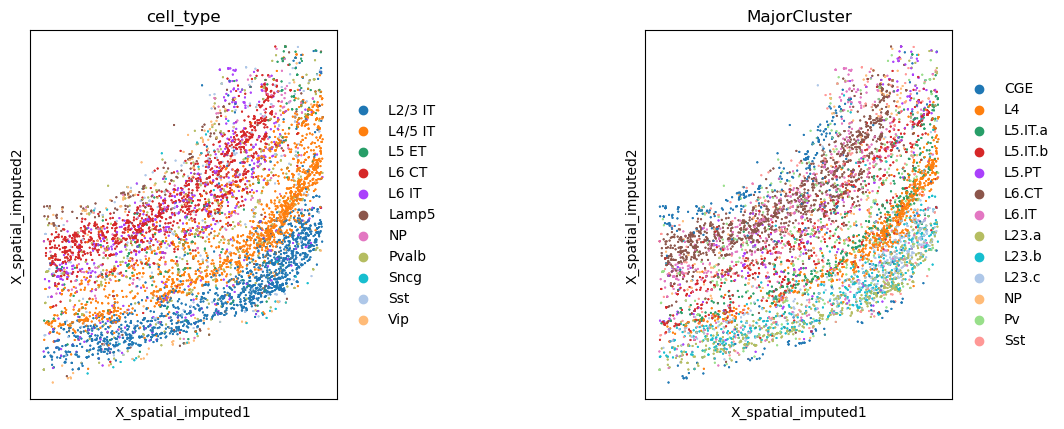

In [18]:
sq.pl.spatial_scatter(adata[adata.obs.modality=="atac",:], library_id=None,spatial_key = 'X_spatial_imputed', 
                      color=["cell_type","MajorCluster"],shape=None,size=1, save="_atac_imputate.pdf")

In [ ]:
adata.write_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/adata_aligned_trained_imputed.h5ad")

use hvg

In [19]:
adata = sc.read_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/adata_aligned_trained_hvg.h5ad")
adata

AnnData object with n_obs × n_vars = 27528 × 5548
    obs: 'x', 'cluster_label', 'subclass_label', 'class_label', 'cluster_color', 'size', 'aggr_num', 'umi.counts', 'gene.counts', 'library_id', 'tube_barcode', 'Seq_batch', 'Region', 'Lib_type', 'Gender', 'Donor', 'Amp_Name', 'Amp_Date', 'Amp_PCR_cyles', 'Lib_Name', 'Lib_Date', 'Replicate_Lib', 'Lib_PCR_cycles', 'Lib_PassFail', 'Cell_Capture', 'Lib_Cells', 'Mean_Reads_perCell', 'Median_Genes_perCell', 'Median_UMI_perCell', 'Saturation', 'Live_percent', 'Total_Cells', 'Live_Cells', 'method', 'exp_component_name', 'mapped_reads', 'unmapped_reads', 'nonconf_mapped_reads', 'total.reads', 'doublet.score', 'domain', 'protocol', 'dataset', 'cell_type', 'batch', 'sample', 'barcode', 'TN', 'UM', 'PP', 'UQ', 'CM', 'tsne_0', 'tsne_1', 'cluster', 'region', 'MajorCluster', 'SubCluster', 'fovID', 'fov_x', 'fov_y', 'volume', 'center_x', 'center_y', 'slice_id', 'sample_id', 'BICCN_cluster_label', 'BICCN_subclass_label', 'BICCN_class_label', 'BICCN_onto

In [20]:
adata.obs.modality.value_counts()

modality
rna     14107
atac     7102
st       6319
Name: count, dtype: int64

In [ ]:
locs = adata.obs.loc[:,['center_x', 'center_y']].to_numpy()
adata.obsm['X_spatial'] = locs.copy()
adata.obs['has_loc'] = adata.obs.modality=='st'
latent = adata.obsm['latent_shared']
z1 = latent[adata.obs.has_loc==0,:]
z2 = latent[adata.obs.has_loc==1,:]
r2 = adata[adata.obs.has_loc==1,:].obsm['X_spatial'].copy()
import ot
p = ot.unif(z1.shape[0])
q = ot.unif(z2.shape[0])
cost_matrix = ot.dist(z1, z2, metric='sqeuclidean')
W = ot.sinkhorn(p, q, cost_matrix, reg=0.01) # ot.sinkhorn_unbalanced,reg_m=1
W = W / W.sum(axis=1, keepdims=True)
r1 = W @ r2

adata.obsm['X_spatial_imputed'] = np.concatenate([r1,r2],axis=0)

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/ot/bregman/_sinkhorn.py:631: RuntimeWarning: divide by zero encountered in divide
  v = b / KtransposeU
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/ot/bregman/_sinkhorn.py:643: UserWarning: Warning: numerical errors at iteration 0
  warnings.warn("Warning: numerical errors at iteration %d" % ii)
/tmp/ipykernel_3543086/637020419.py:14: RuntimeWarning: invalid value encountered in divide
  W = W / W.sum(axis=1, keepdims=True)


/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


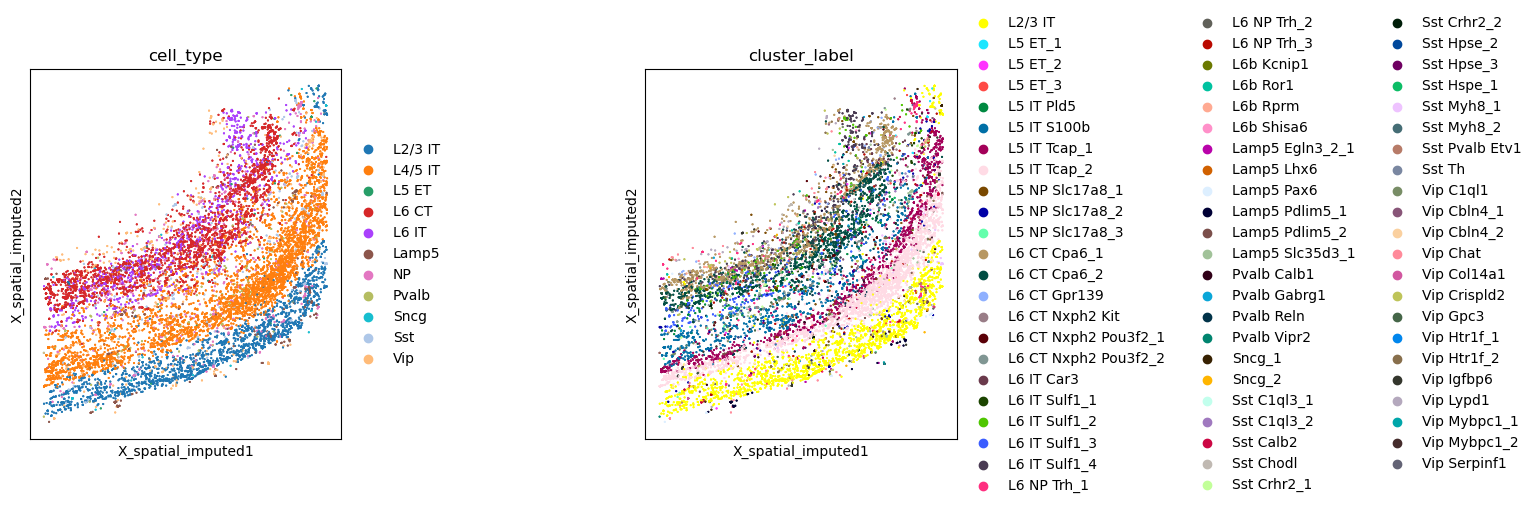

In [23]:
sq.pl.spatial_scatter(adata[adata.obs.modality=="rna",:], library_id=None,spatial_key = 'X_spatial_imputed', 
                      color=["cell_type",'cluster_label'],shape=None,size=1,save="_rna_imputated_hvg.pdf")

/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/scanpy/plotting/_utils.py:488: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/home/bingxing2/ailab/scxlab0179/.conda/envs/bio/lib/python3.11/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


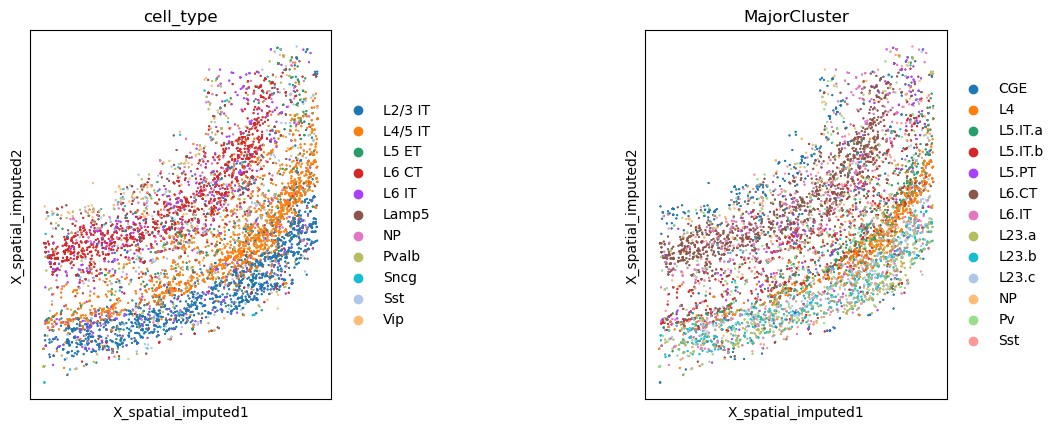

In [24]:
sq.pl.spatial_scatter(adata[adata.obs.modality=="atac",:], library_id=None,spatial_key = 'X_spatial_imputed', 
                      color=["cell_type","MajorCluster"],shape=None,size=1,save="_atac_imputated_hvg.pdf")

In [ ]:
adata.write_h5ad("/home/bingxing2/ailab/group/ai4bio/sunjianle/mouse_pmc/adata_aligned_trained_hvg_imputed.h5ad")